In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv("Powerplant_dataset.csv")

In [3]:
df.head()

,AT,V,AP,RH,PE
0,8.34,40.77,1010.84,90.01,480.48
1,23.64,58.49,1011.40,74.20,445.75
2,29.74,56.90,1007.15,41.91,438.76
3,19.07,49.69,1007.22,76.79,453.09
4,11.80,40.66,1017.13,97.20,464.43


In [4]:
df.isnull().sum()

AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

In [5]:
X=df.drop(columns=["PE"])
y=df["PE"]

In [6]:
X.head()

,AT,V,AP,RH
0,8.34,40.77,1010.84,90.01
1,23.64,58.49,1011.40,74.20
2,29.74,56.90,1007.15,41.91
3,19.07,49.69,1007.22,76.79
4,11.80,40.66,1017.13,97.20


In [7]:
y.head()

0    480.48
1    445.75
2    438.76
3    453.09
4    464.43
Name: PE, dtype: float64

In [8]:
# split out data
from sklearn.model_selection import train_test_split

X_train , X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [9]:
X_train

,AT,V,AP,RH
5487,25.24,63.47,1011.30,66.21
3522,26.09,70.40,1007.41,85.37
6916,26.63,73.68,1015.15,85.13
7544,32.06,71.85,1007.90,56.44
7600,28.70,71.64,1007.11,69.85
...,...,...,...,...
5734,26.25,61.02,1011.47,71.22
5191,29.17,64.79,1016.43,61.05
5390,18.00,43.70,1015.40,61.28
860,26.73,68.84,1010.75,66.83


In [10]:
X_test

,AT,V,AP,RH
2513,29.70,57.35,1005.63,57.35
9411,25.71,71.64,1008.85,77.31
8745,17.83,44.92,1025.04,70.58
9085,9.46,41.40,1026.78,87.58
4950,29.90,64.79,1016.90,48.24
...,...,...,...,...
7204,20.46,51.43,1010.06,83.79
1599,29.70,67.17,1007.31,66.56
5697,14.64,39.58,1011.46,71.90
350,29.47,71.32,1008.07,67.00


In [11]:
df.shape

(9568, 5)

In [12]:
from sklearn.preprocessing import StandardScaler

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

In [13]:
X_train_scaled

array([[ 0.74805289,  0.72006931, -0.32660017, -0.49711722],
       [ 0.86181948,  1.26515721, -0.98521113,  0.8181501 ],
       [ 0.93409473,  1.52314975,  0.32523844,  0.80167494],
       ...,
       [-0.22097078, -0.834965  ,  0.36756563, -0.83554456],
       [ 0.94747903,  1.14245344, -0.41971997, -0.45455637],
       [-1.77355014, -1.19049131,  1.92520594,  0.91837402]])

In [14]:
X_test_scaled

array([[ 1.36255441,  0.24305848, -1.27798491, -1.04586379],
       [ 0.82147733,  1.36986442, -0.74695303,  0.31071896],
       [-0.247116  , -0.73708132,  1.92304887, -0.14668594],
       ...,
       [-0.67970645, -1.15815506, -0.31652036, -0.05697206],
       [ 1.33136451,  1.34463153, -0.87558808, -0.39000089],
       [-0.26474508, -0.26711887,  0.33984824,  1.14397069]])

In [15]:
import torch
import torch.nn as nn

In [16]:
X_train_tensor=torch.tensor(X_train_scaled,dtype=torch.float32)
y_train_tensor=torch.tensor(y_train.values,dtype=torch.float32).view(-1,1)

X_test_tensor=torch.tensor(X_test_scaled,dtype=torch.float32)
y_test_tensor=torch.tensor(y_test.values,dtype=torch.float32).view(-1,1)

In [17]:
X_train_tensor

tensor([[ 0.7481,  0.7201, -0.3266, -0.4971],
        [ 0.8618,  1.2652, -0.9852,  0.8182],
        [ 0.9341,  1.5231,  0.3252,  0.8017],
        ...,
        [-0.2210, -0.8350,  0.3676, -0.8355],
        [ 0.9475,  1.1425, -0.4197, -0.4546],
        [-1.7736, -1.1905,  1.9252,  0.9184]])

In [18]:
type(X_train_scaled)

numpy.ndarray

In [19]:
type(y_train)

pandas.core.series.Series

In [20]:
y_train_tensor

tensor([[442.7500],
        [432.5200],
        [428.8000],
        ...,
        [464.2600],
        [440.4500],
        [484.4400]])

In [21]:
X_test_tensor

tensor([[ 1.3626,  0.2431, -1.2780, -1.0459],
        [ 0.8215,  1.3699, -0.7470,  0.3107],
        [-0.2471, -0.7371,  1.9230, -0.1467],
        ...,
        [-0.6797, -1.1582, -0.3165, -0.0570],
        [ 1.3314,  1.3446, -0.8756, -0.3900],
        [-0.2647, -0.2671,  0.3398,  1.1440]])

In [22]:
from torch.utils.data import TensorDataset,DataLoader

train_dataset=TensorDataset(X_train_tensor, y_train_tensor)
test_dataset=TensorDataset(X_test_tensor,y_test_tensor)

In [23]:
train_loader=DataLoader(train_dataset,batch_size=32,shuffle=True)
test_loader=DataLoader(test_dataset,batch_size=32)

In [24]:
#define ANN model
class ANN(nn.Module):
    def __init__(self):
        super(ANN,self).__init__()

        self.model=nn.Sequential(
            nn.Linear(X_train.shape[1],6),
            nn.ReLU(),

            nn.Linear(6,6),
            nn.ReLU(),

            nn.Linear(6,1),
        )
    def forward(self,x):
        return self.model(x)

In [25]:
import torch.optim as optim

model=ANN()

crietrion=nn.MSELoss()
optimizer=optim.Adam(model.parameters())

In [26]:
# Train the ANN
train_losses = []
val_losses = []

best_val_loss = float("inf")

epochs = 100

for epoch in range(epochs):
    model.train()
    running_loss = 0.0 # tot training loss for 1 epoch
    
    for xb, yb in train_loader:
        # xb = features of 1 batch
        # yb = labels of 1 batch
        optimizer.zero_grad()
        
        outputs = model(xb) # forward prop....predicted outputs for this batch
        loss = crietrion(outputs, yb) # compute loss
        loss.backward() # back prop.. compute gradients
        optimizer.step() # params update
        
        running_loss += loss.item() # loss is a tensor => py float

    epoch_train_loss = running_loss / len(train_loader)
    train_losses.append(epoch_train_loss)


    # Validation
    model.eval()
    running_val_loss = 0.0

    with torch.no_grad(): # no gradients compute
        for xb, yb in test_loader:
            outputs = model(xb)
            loss = crietrion(outputs, yb)
            running_val_loss += loss

    epoch_val_loss = running_val_loss / len(test_loader)
    val_losses.append(epoch_val_loss)







     
    print(f"epoch {epoch+1}/{epochs} ==> train loss = {epoch_train_loss} & val loss = {epoch_val_loss}")

    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        torch.save(model.state_dict(), "best_model.pt") #.pt or .pth

epoch 1/100 ==> train loss = 205136.90755208334 & val loss = 200909.921875
epoch 2/100 ==> train loss = 185174.42975260416 & val loss = 162234.09375
epoch 3/100 ==> train loss = 129504.30712890625 & val loss = 95918.28125
epoch 4/100 ==> train loss = 69053.43927408854 & val loss = 47403.71484375
epoch 5/100 ==> train loss = 35205.9336344401 & val loss = 25249.302734375
epoch 6/100 ==> train loss = 20457.36330973307 & val loss = 15978.5947265625
epoch 7/100 ==> train loss = 13991.63823038737 & val loss = 11463.6650390625
epoch 8/100 ==> train loss = 10055.142378743489 & val loss = 8110.0537109375
epoch 9/100 ==> train loss = 7042.152088419596 & val loss = 5572.71044921875
epoch 10/100 ==> train loss = 4826.930299886068 & val loss = 3850.383544921875
epoch 11/100 ==> train loss = 3369.3996978759765 & val loss = 2725.46533203125
epoch 12/100 ==> train loss = 2399.7674947102864 & val loss = 1958.478271484375
epoch 13/100 ==> train loss = 1741.4185365041096 & val loss = 1426.7613525390625
e

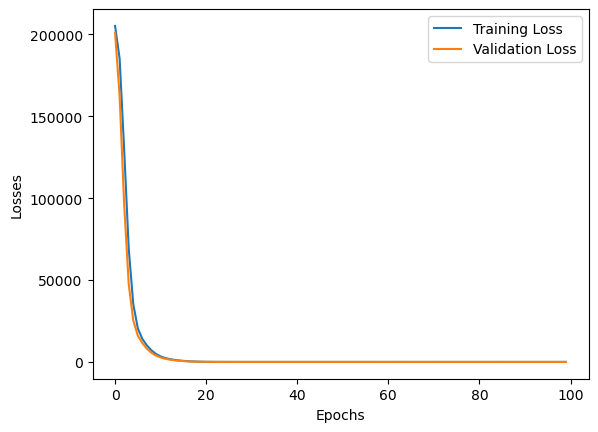

In [31]:
import matplotlib.pyplot as plt

loss_df = pd.DataFrame({
    "Training Loss": train_losses,
    "Validation Loss": val_losses
})

plt.plot(loss_df["Training Loss"], label = "Training Loss")
plt.plot(loss_df["Validation Loss"], label = "Validation Loss")

plt.xlabel("Epochs")
plt.ylabel("Losses")

plt.legend()

In [32]:
# loading the best model
model.load_state_dict(torch.load("best_model.pt"))

<All keys matched successfully>

In [33]:
model.eval()
with torch.no_grad():
    train_pred=model(X_train_tensor)
    test_pred=model(X_test_tensor)

    train_mse=crietrion(train_pred,y_train_tensor)
    test_mse=crietrion(test_pred,y_test_tensor)

print("Training mse:",train_mse.item())
print("Testing mse:",test_mse.item())

Training mse: 20.380863189697266
Testing mse: 18.68317413330078


In [34]:
from sklearn.metrics import r2_score

print("R2 score:",r2_score(y_test,test_pred))

R2 score: 0.9347071329136623
